# Gráfico 5: mapa de calor de correlaciones
    
¿Cuánto se mueve el precio de la vivienda junto con el turismo (Hipótesis 1), la inflación (Hipótesis 2) y el PIB (Hipótesis 3). Es asociación, no causalidad.

**Datos:** `merge_todos_paises.csv` (54 países, 408 observaciones) y, para la comprobación, `merge_panel_25.csv` (25 países con serie completa).

## 1 Librerías y funciones propias (src/utils/archivos.py)

In [1]:
import sys
sys.path.append("..")
from utils.archivos import cargar_dataset, guardar_grafico

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

## 2 Cargo los datos

In [2]:
datos_mergeados = cargar_dataset("merge_todos_paises.csv")
datos_mergeados_2 = cargar_dataset("merge_panel_25.csv")
print(datos_mergeados.shape, datos_mergeados_2.shape)

FileNotFoundError: [Errno 2] No such file or directory: 'c:\\Users\\Agus\\Bootcamp\\proyectos\\4_PROYECTO_2 EDA\\src\\data\\Mergeados\\merge_panel_25.csv'

## 3 Mapa de calor con todas las observaciones

Guardado: c:\Users\Agus\Bootcamp\proyectos\4_PROYECTO_2 EDA\src\visualizaciones\05_correlaciones.png


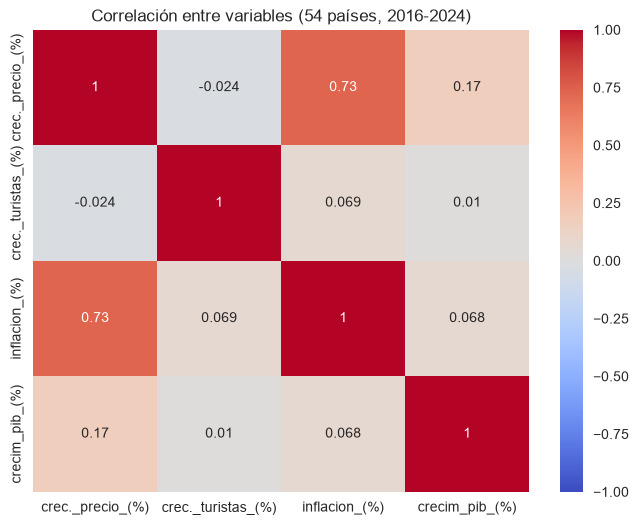

In [3]:
columnas = ["crec._precio_(%)", "crec._turistas_(%)", "inflacion_(%)", "crecim_pib_(%)"]
corr = datos_mergeados[columnas].corr()

plt.style.use("seaborn-v0_8")
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre variables (54 países, 2016-2024)")
guardar_grafico("05_correlaciones.png")
plt.show()

## 4 Comprobación de robustez

Si la correlación del precio con cada variable cambia mucho según la muestra, el resultado es frágil.

In [4]:
sin_pandemia = datos_mergeados[~datos_mergeados["anio"].between(2020, 2022)]
print("Sin 2020-2022:")
print(sin_pandemia[columnas].corr().round(2)["crec._precio_(%)"])
print()
print("Panel de 25 países:")
print(datos_mergeados_2[columnas].corr().round(2)["crec._precio_(%)"])

Sin 2020-2022:
crec._precio_(%)      1.00
crec._turistas_(%)   -0.21
inflacion_(%)         0.10
crecim_pib_(%)        0.22
Name: crec._precio_(%), dtype: float64

Panel de 25 países:


NameError: name 'datos_mergeados_2' is not defined

## Lectura del gráfico

*(Escribe aquí en 1-2 frases qué se observa.)*